# Lab 2 : Classification

## G3 SDI - Machine Learning

In this lab, we will tackle a binary classification problem. We are going to use the MNIST dataset, which contains 28x28 images of handwritten digits. More precisely, our goal will be to distinguish between 3s and 5s using logistic regression and K-nearest neighbors.

### Instructions
* Rename your notebook with your surnames as `lab2_Name1_Name2.ipynb`, and include your names in the notebook.
* Your code, and its output, must be commented !
* Please upload your notebook on Moodle in the dedicated section before the deadline.

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">
Report written by FERNANDES--STRAG, TORRES--LEGUET, 22/10/26.
</div>

In [120]:
# Import usual libraries
import numpy as np
from matplotlib import pyplot as plt

**Q1.** Load the data from the `.npy` files included in the archive (use `np.load`). How many examples are there ? How many features ? What do the values of the features represent ?

In [121]:
data_3 = np.load('data3.npy')
data_5 = np.load('data5.npy')

print("Data 3:", data_3.shape)
print("Data 5:", data_5.shape)

print("Range des valeurs des features :", data_3.min(), data_3.max())

Data 3: (1037, 784)
Data 5: (963, 784)
Range des valeurs des features : 0 255


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On ouvre les fichiers `data3.npy` et `data5.npy` sous forme de matrice numpy, on recupère des matrices de taille $(N, D)$ où le nombre d'exemples $N$ vaut 1037 pour la classe correspond au chiffre 3, et 963 pour le chiffre 5. Les classes sont à peu près équilibrées, ce qui est important à savoir pour la suite (interprétation des métriques).

Le nombre de features $D$ vaut 784 pour tous les exemples, soit des images de 28x28 applaties en vecteur de taille 784.
Il y a donc une feature par pixel, et chaque feature correspond à l'échelle de gris (0=noir, 255=blanc, entre les deux=gris) du pixel correspondant.

</div>

**Q2.** Display a few examples of 3, and a few examples of 5 (use `plt.imshow`). Comment.

Text(0.5, 0.98, 'Exemples de 3 et de 5 tirés aléatoirement du dataset')

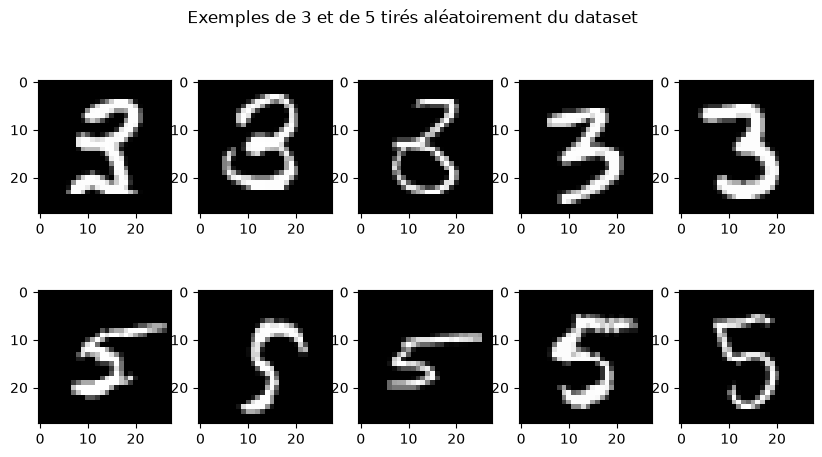

In [122]:
# data_3 : (N, 784) full of 3s
# data_5 : (N, 784) full of 5s

# lets plot a few 3s and a few 5s

fig, axs = plt.subplots(2, 5, figsize=(10, 5))

for j in range(5):
        rand1 = np.random.randint(0, data_3.shape[0])
        rand2 = np.random.randint(0, data_5.shape[0])
        axs[0, j].imshow(data_3[rand1].reshape(28, 28), cmap='gray')
        axs[1, j].imshow(data_5[rand2].reshape(28, 28), cmap='gray')
plt.suptitle("Exemples de 3 et de 5 tirés aléatoirement du dataset")

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Les deux classes sont bien distinguables à l'oeil nu. L'intérêt de ce TP est donc de savoir si un modèle qui lit la valeur de tous les pixels d'une image peut faire de même !

Certains sont quand même mal écrits et ressemblent très peu à des 3 / des 5.

</div>

**Q3.** Create a variable X which contains all the images (use `np.vstack`), and a variable y which encodes the class.

Normalize the features between 0 and 1.

In [123]:
X = np.vstack((data_3, data_5)) # (1037, 784) vstack (963, 784) -> (2000, 784)
X = X / 255.0 # plage 0->255 ramenée entre 0 et 1

y = np.hstack((np.zeros(data_3.shape[0]), np.ones(data_5.shape[0])))
# on choisit la convention : 0 pour la classe des chiffre '3', 1 pour les '5'

print(X.shape)
print(y.shape)

(2000, 784)
(2000,)


**Q4.** Split the dataset into a training set and a test set, using 20% of the original dataset for the test set. Do not forget to set the random state.

In [132]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=np.random.RandomState(42))
# s'assure aussi de mélanger les données

print("Tailles après split")
print("X_train, y_train:", X_train.shape, y_train.shape)
print("X_test, y_test:", X_test.shape, y_test.shape)

Tailles après split
X_train, y_train: (1600, 784) (1600,)
X_test, y_test: (400, 784) (400,)


**Q5.** Train a logistic regression model on the training set (see documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)). Recall how the coefficients are obtained.

What does scikit-learn do by default that does not match what we studied during the lecture ?

In [133]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

print(model.coef_.shape)
print(model.intercept_)

print("Score sur le train set:", model.score(X_train, y_train)) # model.score calcule l'accuracy

(1, 784)
[3.14088116]
Score sur le train set: 0.9925


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On lance l'entraînement de la régression logisitique avec `fit()`, on récupère bien le nombre de coefficients attendus : 784 + l'intercept. Le modèle est celui de la régression logistique :

$$\sigma(w^Tx + w_0), w \in \mathbb{R^D}, w_0 \in \mathbb{R} $$

Dont les valeurs de $w$ sont trouvés par maximisation de log-vraisemblance, étant donné l'hypothèse sur la vraisemblance des données : 

$$y|x;w \sim B(\sigma(w^Tx + w_0)) $$

Dont une solution approchée est trouvée par une méthode d'optimisation (pas de solution analytique existante).
Le comportement par défaut de scikit-learn pour la régression logistique est celui de choisir le solver `lbfgs` (limited memory Broyden–Fletcher–Goldfarb–Shanno algorithm), qui après des recherches, est une méthode de quasi-Netwon efficiente en terme de mémoire.

Par défaut également, scikit-learn applique de la régularisation L2, ce qui revient à introduire un terme de pénalité dans le coût, qui devient alors :

$$\mathcal{L}(w) = - \sum_{i=1}^N \Big( y_i \text{log}(\sigma(w^Tx_i+w_0)) + (1-y_i) \text{log}(1-\sigma(w^Tx_i+w_0)) \Big) + \lambda ||w||_2$$

(on ne régularise pas l'intercept $w_0$)

</div>

**Q6.** Compute the accuracy on the test set.

In [96]:
print("Accuracy sur le test set:", model.score(X_test, y_test))

Accuracy sur le test set: 0.955


<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

On obtient 95.5%, ce qui est bien meilleur que le prédicteur au hasard (on obtiendrait 50% environ étant donné que les classes sont équilibrées)

</div>

**Q7.** Display the confusion matrix from the test set (add label names), and interpret it.

Accuracy: 95.50%
Rappel: 95.43%
Précision: 95.43%
F-score: 95.43%


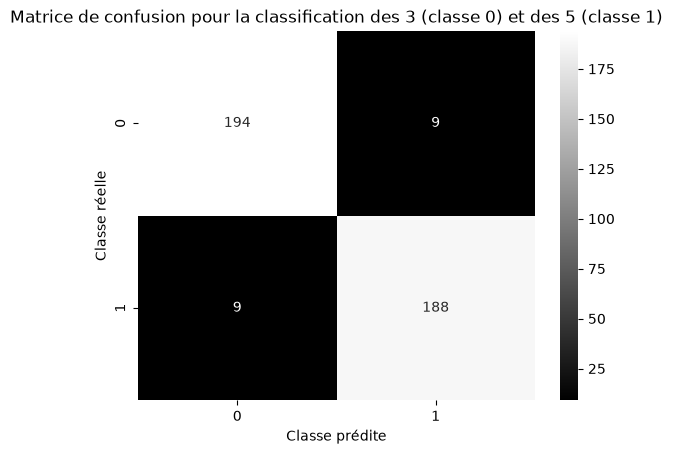

In [97]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

M = confusion_matrix(y_test, model.predict(X_test))

sns.heatmap(M, annot=True, cmap='gray', fmt=".0f")
plt.title("Matrice de confusion pour la classification des 3 (classe 0) et des 5 (classe 1)")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

TN, FP, FN, TP = M[0, 0], M[0, 1], M[1, 0], M[1, 1]
rappel = TP / (TP + FN)
precision = TP / (TP + FP)
F = 2 * (precision * rappel) / (precision + rappel)

print(f"Accuracy: {100*(TP + TN)/(TP + TN + FP + FN):.2f}%")
print(f"Rappel: {100*rappel:.2f}%")
print(f"Précision: {100*precision:.2f}%")
print(f"F-score: {100*F:.2f}%")

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Etant donné que les classes sont équilibrées, on retrouve ici le fait que l'accuracy est un bon moyen de mesurer les performances du modèle.
On constate également que les prédictions du modèle sont "symétriques", car il confond autant les 5 en 3 et les 3 en 5. C'est d'ailleurs pourquoi rappel = précision = F1 score ici.

Au global donc, les performances sont très bonnes car il arrive à séparer les 3 des 5 de manière fiable.

</div>

**Q8.** Display an example where a 3 was mistaken for 5, and vice versa. Comment.

Text(0.5, 0.98, 'Exemples de faux négatifs et de faux positifs sur le test set')

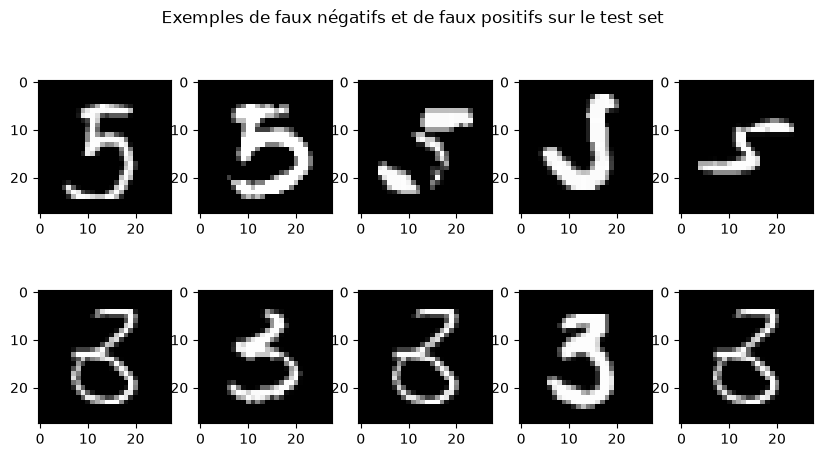

In [136]:
predictions = model.predict(X_test)

# indices des exemples où le modèle a prédit 3 mais c'était en fait un 5
faux_neg = np.where((predictions == 0) & (y_test == 1))[0] # faux négatif
faux_pos = np.where((predictions == 1) & (y_test == 0))[0] # faux positif

fig, axs = plt.subplots(2, 5, figsize=(10, 5))

for j in range(5):
        rand1 = np.random.randint(0, len(faux_neg))
        rand2 = np.random.randint(0, len(faux_pos))
        axs[0, j].imshow(X_test[faux_neg[rand1]].reshape(28, 28), cmap='gray')
        axs[1, j].imshow(X_test[faux_pos[rand2]].reshape(28, 28), cmap='gray')
plt.suptitle("Exemples de faux négatifs et de faux positifs sur le test set")

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Les exemples sur lesquels le modèle se trompe sont dans la plupart de cas des exemples "pathologiques", des chiffres mal écrits.

</div>

**Q9.** As we have seen during the lecture, the logistic regression model does not directly output a 0 or a 1, but rather the probability of being 0 or 1 (given x), which can be accessed with the `.predict_proba` attribute. This probability is then compared to a threshold to output the prediction, the default threshold being 0.5.

Recall what is the underlying assumption of using a threshold of 0.5.

Display the evolution of the precision and recall (using the 5s as the reference class), as well as the F1-score, when the threshold varies between 0 and 1. Comment.

In [146]:
model.predict_proba(X_test).shape

(400, 2)

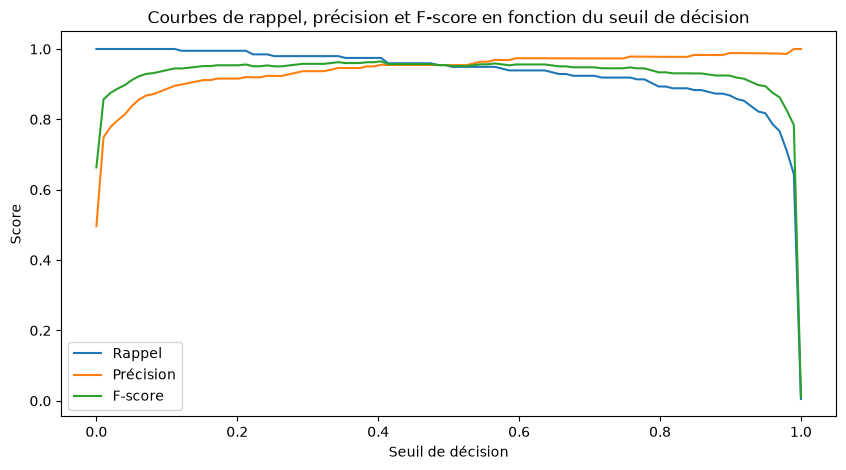

In [162]:
eps = 1e-8 # on exclue les valeurs de seuil 0 et 1 pour stabilité numérique
thresholds = np.linspace(0 + eps, 1 - eps, 100)
rappels = []
precisions = []
fs = []

# model.predict_proba(X_test) -> (N, 2) avec proba d'appartenance à la classe 0 et à la classe 1
# donc on prend la colonne 1 pour utiliser 5 en classe de référence
proba_classe_ref = model.predict_proba(X_test)[:, 1]

for t in thresholds:
    predictions = (proba_classe_ref >= t).astype(int) # prédictions des "5" avec le seuil t

    # mêmes calculs qu'en Q7
    M = confusion_matrix(y_test, predictions)
    TN, FP, FN, TP = M[0, 0], M[0, 1], M[1, 0], M[1, 1]
    rappel = TP / (TP + FN)
    precision = TP / (TP + FP)
    F = 2 * (precision * rappel) / (precision + rappel)
    
    rappels.append(rappel)
    precisions.append(precision)
    fs.append(F)

plt.figure(figsize=(10, 5))

plt.plot(thresholds, rappels, label="Rappel")
plt.plot(thresholds, precisions, label="Précision")
plt.plot(thresholds, fs, label="F-score")

plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Courbes de rappel, précision et F-score en fonction du seuil de décision")
plt.legend()

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Le choix du seuil de 0.5 découle du choix du coût 0-1 ($l_{01}$), et de la règle de Bayes de la classification, qui impose de prendre la classe k:

$$\text{argmax}_k P(C_k | x)$$

Dans le cas binaire, où seuls les termes $P(y=0|x)$ et $P(y=1|x)$ entrent en jeu, cette règle équivant à prendre le plus grand des deux, c'est-à-dire celui qui dépasse 0.5.

Quand on augmente le seuil, le rappel passe de 1 à 0. En effet, un seuil de 0 équivant à prédire que des 5, donc la proportions de 5 bien identifiés (ie, le rappel) est bien de 100%. A mesure qu'on est plus "sélectif" en augmentant le seuil, on exclue des 3 mais aussi des 5, ce qui fait que le rappel diminue.

A l'inverse, la précision (proportion des exemples correctement classifiés parmis les positifs prédits) passe de 0 à 1 quand on augmente le seuil. En effet, quand le seuil est petit, on ne prédit que très peu de 5, donc la proportion de prédictions correctes parmis les prédits positifs est petite.

Enfin, le F-score atteint son pic de 96.5% autour d'un seuil de décision de 0.4, bien qu'il reste relativement plat pour des valeurs de seuil entre 0.2 et 0.6. Le F-score permet de trouver le régime où la précision et le rappel sont tous les deux bons (c'est la moyenne harmonique du rappel et de la précision).

Il n'existe donc pas une unique valeur optimale du seuil de décision, car elle dépend du cahier des charges, c'est-à-dire notre "préférence" à minimiser rappel ou précision.

</div>

**Q10.** Lastly, we would like to check the performance of KNN on this dataset. To do so, select the optimal value of $K$ by cross-validation on the training set, and then compute the accuracy score of the optimal KNN on the test set. Comment.

In [181]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import KFold

# on reprend et modifie le code du lab 1 (Part II Q4)
# on se base sur l'accuracy pour choisir le meilleur K

kf = KFold(n_splits=5)

Ks = list(range(1, 20, 2))
accuracies = [] # liste des accuracies pour chaque K

for i, K in enumerate(Ks):
    accs = [] # liste des accuracies pour chaque fold
    for train_index, val_index in kf.split(X_train):
        X_train_fold, X_val_fold = X_train[train_index], X_train[val_index]
        y_train_fold, y_val_fold = y_train[train_index], y_train[val_index]

        model_knn = KNeighborsClassifier(n_neighbors=K)
        model_knn.fit(X_train_fold, y_train_fold)

        accs.append(model_knn.score(X_val_fold, y_val_fold))
    
    accuracies.append(np.mean(accs))

Meilleur K: 5 avec une accuracy moyenne de 0.9769


Text(0.5, 1.0, 'Accuracy moyenne sur les folds de validation en fonction de K (meilleur K = 5)')

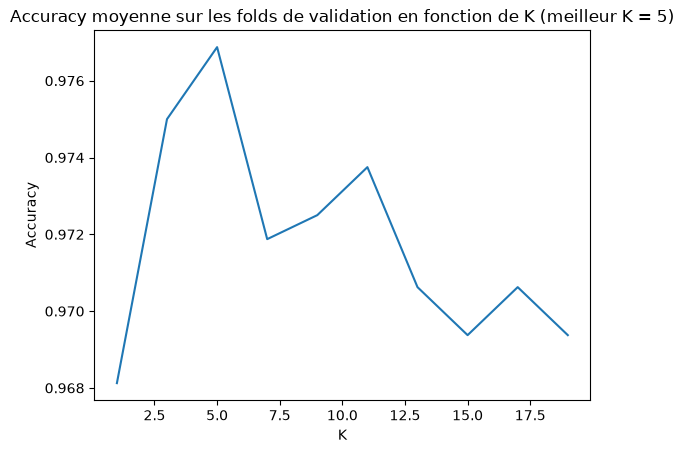

In [195]:
# on récupère le K qui a donné la meilleure accuracy moyenne sur les folds de validation
best_idx = np.argmax(accuracies)
best_K = Ks[best_idx]

print(f"Meilleur K: {best_K} avec une accuracy moyenne de {accuracies[best_idx]:.4f}")

plt.plot(Ks, accuracies)
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.title(f"Accuracy moyenne sur les folds de validation en fonction de K (meilleur K = {best_K})")

Accuracy: 98.50%
Rappel: 98.48%
Précision: 98.48%
F-score: 98.48%


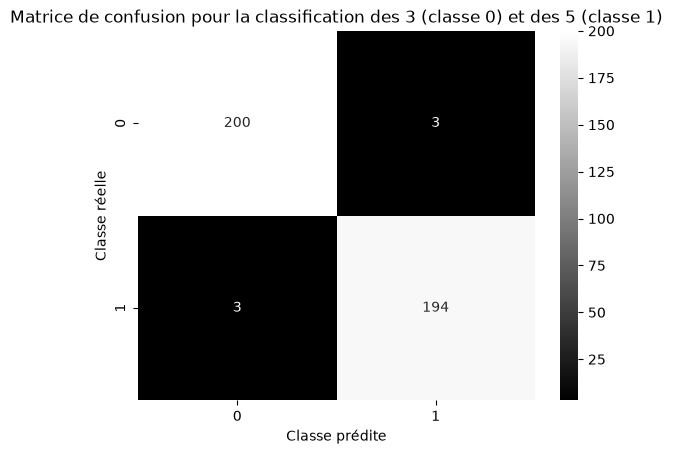

In [199]:
# on le fait alors tourner sur l'ensemble du train set, puis on évalue sur le test set
model_knn = KNeighborsClassifier(n_neighbors=best_K)
model_knn.fit(X_train, y_train)

M = confusion_matrix(y_test, model_knn.predict(X_test))

sns.heatmap(M, annot=True, cmap='gray', fmt=".0f")
plt.title("Matrice de confusion pour la classification des 3 (classe 0) et des 5 (classe 1)")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

TN, FP, FN, TP = M[0, 0], M[0, 1], M[1, 0], M[1, 1]
rappel = TP / (TP + FN)
precision = TP / (TP + FP)
F = 2 * (precision * rappel) / (precision + rappel)

print(f"Accuracy: {100*(TP + TN)/(TP + TN + FP + FN):.2f}%")
print(f"Rappel: {100*rappel:.2f}%")
print(f"Précision: {100*precision:.2f}%")
print(f"F-score: {100*F:.2f}%")

<div style="background-color: rgba(255, 255, 0, 0.15); padding: 8px;">

Après la procédure de validation croisée (5-folds), on trouve la valeur de K optimale qui vaut 5.
On entraîne ensuite un nouveau modèle sur l'ensemble du train set avec K=5, et on mesure ensuite ses performances sur le test set : 98.5%.

C'est légèrement meilleur que le résultat obtenu précédemment avec la régression logistique.

</div>